**RQ2-01. Environment and Directory Initialization**
**Objective:** Initialize the computational environment and define consistent input and output directories for class imbalance experiments.

**Input**: Existing Google Drive workspace, RQ1 model selection artifacts, and preprocessed datasets.

**Procedure:** Mount Google Drive, import the required libraries, define directory paths, and verify the availability of essential artifacts.

**Output:** Validated paths for RQ1, RQ2, preprocessing, and train-validation datasets.

**Methodological consideration:** RQ2 reuses the established data partition and model configuration. No additional train-test splitting is performed.

In [ ]:
# ============================================================
# RQ2-01 — ENVIRONMENT AND DIRECTORY INITIALIZATION
# ============================================================

%pip -q install imbalanced-learn

from google.colab import drive
from pathlib import Path

import json
import time
import gc
import sys
import platform

import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    confusion_matrix,
    precision_recall_curve
)

from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTENC

# Kết nối Google Drive.
drive.mount("/content/drive")

SEED = 42
THRESHOLD_REFERENCE = 0.5

# Giữ nguyên thư mục dự án.
ROOT = Path(
    "/content/drive/Shareddrives/"
    "M(anchine) L(earning)/Output"
)

EXP = ROOT / "ML_Experiments"

PP_DIR = ROOT / "Preprocessing"
SPLIT_DIR = ROOT / "Train_Validation_Test"

RQ1_DIR = EXP / "RQ1"
RQ2_DIR = EXP / "RQ2"

MODEL_DIR = RQ2_DIR / "models"
RESULT_DIR = RQ2_DIR / "results"
FIGURE_DIR = RQ2_DIR / "figures"

# Các thư mục này đã được tạo trong RQ1.
for folder in [MODEL_DIR, RESULT_DIR, FIGURE_DIR]:
    assert folder.is_dir(), f"Thiếu thư mục: {folder}"

assert PP_DIR.is_dir()
assert SPLIT_DIR.is_dir()

# Import module feature engineering đã sử dụng
# trong Data Preparation và luồng Flask.
sys.path.insert(0, str(PP_DIR))

import fraud_preprocessing as fp

print("PASS: RQ2 environment initialized.")
print("Output directory:", RQ2_DIR)

Mounted at /content/drive
PASS: RQ2 environment initialized.
Output directory: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ2


In [ ]:
# ============================================================
# RQ2-02 — LOAD SELECTED MODEL FROM RQ1
# ============================================================

selection_path = (
    RQ1_DIR / "results" / "selected_model.json"
)

assert selection_path.is_file()

with open(selection_path, "r", encoding="utf-8") as f:
    rq1_selection = json.load(f)

# Kiểm tra kết quả lựa chọn RQ1.
assert rq1_selection["selected_model"] == "XGBoost"
assert rq1_selection["preprocessing_family"] == "Tree"
assert rq1_selection["feature_set"] == "Full_Features"
assert rq1_selection["test_used_for_selection"] is False

# Tải XGBoost baseline.
baseline_model_path = (
    RQ1_DIR / "models" / "XGBoost.joblib"
)

assert baseline_model_path.is_file()

baseline_model = joblib.load(baseline_model_path)

assert baseline_model.n_features_in_ == 13

# Xác nhận baseline chưa xử lý class imbalance.
assert baseline_model.get_params()[
    "scale_pos_weight"
] == 1.0

print("Selected algorithm:", rq1_selection["selected_model"])
print("Preprocessing:", rq1_selection["preprocessing_family"])
print("Feature set:", rq1_selection["feature_set"])
print("Validation AP:", rq1_selection["selection_metric_value"])

print("\nPASS: RQ1 configuration verified.")

Selected algorithm: XGBoost
Preprocessing: Tree
Feature set: Full_Features
Validation AP: 0.9978634424566084

PASS: RQ1 configuration verified.


In [ ]:
# ============================================================
# RQ2-03 — LOAD AND VALIDATE DATA
# ============================================================

train_path = (
    PP_DIR / "3.2.7_Tree_Train_60pct.parquet"
)

val_path = (
    PP_DIR / "3.2.7_Tree_Validation_20pct.parquet"
)

assert train_path.is_file()
assert val_path.is_file()

train_df = pd.read_parquet(train_path)
val_df = pd.read_parquet(val_path)

TARGET = "isFraud"

X_train = train_df.drop(columns=[TARGET])
y_train = train_df[TARGET].astype("int8")

X_val = val_df.drop(columns=[TARGET])
y_val = val_df[TARGET].astype("int8")

# Kiểm tra dữ liệu và target.
assert X_train.shape[1] == 13
assert X_val.shape[1] == 13

assert X_train.columns.equals(X_val.columns)
assert X_train.index.is_unique
assert X_val.index.is_unique

assert X_train.index.intersection(X_val.index).empty
assert y_train.isin([0, 1]).all()
assert y_val.isin([0, 1]).all()

# Kiểm tra đúng thứ tự features của XGBoost.
assert list(X_train.columns) == list(
    baseline_model.feature_names_in_
)

# Thống kê số lượng giao dịch.
n_negative = int((y_train == 0).sum())
n_positive = int((y_train == 1).sum())

class_ratio = n_negative / n_positive

print("Train:", X_train.shape)
print("Validation:", X_val.shape)

print("Non-fraud Train:", n_negative)
print("Fraud Train:", n_positive)
print("Fraud rate:", round(y_train.mean() * 100, 4), "%")

print("Class imbalance ratio:", round(class_ratio, 2))
print("\nPASS: Data ready for RQ2.")

Train: (3817572, 13)
Validation: (1272524, 13)
Non-fraud Train: 3812644
Fraud Train: 4928
Fraud rate: 0.1291 %
Class imbalance ratio: 773.67

PASS: Data ready for RQ2.


In [ ]:
# ============================================================
# RQ2-04 — ORIGINAL STRATEGY
# ============================================================

from sklearn.metrics import (
    average_precision_score, roc_auc_score,
    precision_score, recall_score, f1_score,
    accuracy_score, confusion_matrix
)

# Hàm đánh giá thống nhất cho tất cả strategies.
def evaluate_strategy(y_true, scores, threshold=0.5):

    scores = np.asarray(scores, dtype=float)

    assert len(scores) == len(y_true)
    assert np.isfinite(scores).all()
    assert ((scores >= 0) & (scores <= 1)).all()

    predictions = (scores >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true, predictions, labels=[0, 1]
    ).ravel()

    return {
        "AP": float(average_precision_score(y_true, scores)),
        "ROC_AUC": float(roc_auc_score(y_true, scores)),
        "Accuracy": float(accuracy_score(y_true, predictions)),
        "Precision_at_0_5": float(
            precision_score(y_true, predictions, zero_division=0)
        ),
        "Recall_at_0_5": float(
            recall_score(y_true, predictions, zero_division=0)
        ),
        "F1_at_0_5": float(
            f1_score(y_true, predictions, zero_division=0)
        ),
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "TN": int(tn)
    }


# Đọc Validation scores đã lưu trong RQ1.
original_score_path = (
    RQ1_DIR / "results"
    / "XGBoost_validation_scores.parquet"
)

original_scores_df = pd.read_parquet(
    original_score_path
)

# Đối chiếu theo transaction index, không dựa vào
# vị trí dòng trong DataFrame.
assert original_scores_df.index.is_unique
assert original_scores_df.index.difference(X_val.index).empty
assert X_val.index.difference(original_scores_df.index).empty

original_scores_df = original_scores_df.reindex(
    X_val.index
)

assert np.array_equal(
    original_scores_df["isFraud"].to_numpy(),
    y_val.to_numpy()
)

original_scores = original_scores_df[
    "fraud_score"
].to_numpy()

original_metrics = evaluate_strategy(
    y_val, original_scores
)

# Đối chiếu AP với kết quả RQ1 đã lựa chọn.
assert np.isclose(
    original_metrics["AP"],
    rq1_selection["selection_metric_value"],
    atol=1e-8
)

# Giữ một bản scores trong thư mục RQ2 để các
# bước visualization và RQ3 đọc nhất quán.
original_scores_df.to_parquet(
    RESULT_DIR / "Original_validation_scores.parquet",
    index=True
)

rq2_results = [{
    "Strategy": "Original",
    "Train_Records": len(y_train),
    "Train_Fraud": int(y_train.sum()),
    **original_metrics
}]

print("Original AP:", round(original_metrics["AP"], 6))
print("Original Recall:", round(original_metrics["Recall_at_0_5"], 6))
print("Original FP:", original_metrics["FP"])
print("Original FN:", original_metrics["FN"])

print("\nPASS: Original baseline verified.")

Original AP: 0.997863
Original Recall: 0.99574
Original FP: 1
Original FN: 7

PASS: Original baseline verified.


In [ ]:
# ============================================================
# RQ2-05 — CLASS WEIGHT STRATEGY
# ============================================================

# Tính trọng số trực tiếp từ Train.
scale_pos_weight = n_negative / n_positive

print("scale_pos_weight =", round(scale_pos_weight, 4))

# Clone mô hình baseline để giữ nguyên hyperparameters.
weighted_model = clone(baseline_model)

# Chỉ thay đổi tham số xử lý mất cân bằng.
weighted_model.set_params(
    scale_pos_weight=float(scale_pos_weight)
)

print("\nTraining XGBoost with Class Weight...")

start = time.perf_counter()

weighted_model.fit(
    X_train,
    y_train
)

training_seconds = time.perf_counter() - start

# Đánh giá trên Validation gốc, chưa resampling.
weighted_scores = weighted_model.predict_proba(
    X_val
)[:, 1]

weighted_metrics = evaluate_strategy(
    y_val,
    weighted_scores
)

# Lưu mô hình ngay sau khi huấn luyện.
weighted_model_path = (
    MODEL_DIR / "Class_Weight.joblib"
)

joblib.dump(
    weighted_model,
    weighted_model_path
)

# Lưu scores, nhãn và transaction index.
weighted_scores_df = pd.DataFrame({
    "fraud_score": weighted_scores,
    "isFraud": y_val.to_numpy()
}, index=X_val.index)

weighted_scores_df.to_parquet(
    RESULT_DIR / "Class_Weight_validation_scores.parquet",
    index=True
)

# Cập nhật danh sách kết quả RQ2.
rq2_results = [
    row for row in rq2_results
    if row["Strategy"] != "Class_Weight"
]

rq2_results.append({
    "Strategy": "Class_Weight",
    "Train_Records": len(y_train),
    "Train_Fraud": int(y_train.sum()),
    **weighted_metrics
})

# Lưu checkpoint.
pd.DataFrame(rq2_results).to_csv(
    RESULT_DIR / "rq2_comparison.csv",
    index=False
)

print("\nCLASS WEIGHT RESULTS")
print("AP:", round(weighted_metrics["AP"], 6))
print("Precision:", round(weighted_metrics["Precision_at_0_5"], 6))
print("Recall:", round(weighted_metrics["Recall_at_0_5"], 6))
print("F1:", round(weighted_metrics["F1_at_0_5"], 6))
print("FP:", weighted_metrics["FP"])
print("FN:", weighted_metrics["FN"])

print("Training seconds:", round(training_seconds, 2))
print("Saved model:", weighted_model_path)

# Giải phóng bộ nhớ trước khi chạy SMOTENC.
del weighted_model, weighted_scores, weighted_scores_df
gc.collect()

print("\nPASS: Class Weight completed.")

scale_pos_weight = 773.6696

Training XGBoost with Class Weight...

CLASS WEIGHT RESULTS
AP: 0.998196
Precision: 0.992718
Recall: 0.99574
F1: 0.994227
FP: 12
FN: 7
Training seconds: 89.03
Saved model: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ2/models/Class_Weight.joblib

PASS: Class Weight completed.


In [ ]:
# ============================================================
# RQ2-06A — SMOTENC RESAMPLING ON TRAIN ONLY
# ============================================================

# Sau khi Class Weight đã hoàn thành,
# giải phóng Train đã preprocessing để tiết kiệm RAM.
del train_df, val_df, X_train, y_train
gc.collect()

# ------------------------------------------------------------
# STEP 1. Đọc Train trước preprocessing
# ------------------------------------------------------------

raw_train_path = (
    SPLIT_DIR / "3.2.8_Train_60pct.parquet"
)

assert raw_train_path.is_file()

base_columns = fp.BASE_FEATURES
target_column = fp.TARGET

raw_train = pd.read_parquet(
    raw_train_path,
    columns=base_columns + [target_column]
)

X_raw = raw_train[base_columns].copy()
y_raw = raw_train[target_column].astype("int8")

# Kiểm tra nhãn và dữ liệu.
assert len(y_raw) == n_negative + n_positive
assert int(y_raw.sum()) == n_positive
assert X_raw["type"].isin(fp.TRANSACTION_TYPES).all()

print("Raw Train:", X_raw.shape)
print("Fraud before SMOTENC:", int(y_raw.sum()))

# ------------------------------------------------------------
# STEP 2. Scaling numeric features cho SMOTENC
# ------------------------------------------------------------
# Đây là scaler phục vụ tìm nearest neighbors,
# không phải Tree preprocessor của Flask.

numeric_base = [
    "step",
    "amount",
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest"
]

smote_scaler = StandardScaler()

X_smote_input = X_raw.copy()

X_smote_input[numeric_base] = (
    smote_scaler.fit_transform(
        X_raw[numeric_base]
    )
)

# Giữ type ở dạng categorical.
X_smote_input["type"] = (
    X_smote_input["type"].astype("category")
)

# ------------------------------------------------------------
# STEP 3. Khai báo SMOTENC
# ------------------------------------------------------------
# 0.02 = số Fraud / số Non-Fraud sau resampling.
# KHÔNG phải Fraud chiếm 2% tổng số giao dịch.

SMOTENC_RATIO = 0.02

assert SMOTENC_RATIO > (
    n_positive / n_negative
), "Sampling ratio phải lớn hơn tỷ lệ ban đầu."

sampler = SMOTENC(
    categorical_features=["type"],
    sampling_strategy=SMOTENC_RATIO,
    k_neighbors=5,
    random_state=SEED
)

print("\nRunning SMOTENC...")

start_smote = time.perf_counter()

X_resampled_scaled, y_resampled = (
    sampler.fit_resample(
        X_smote_input,
        y_raw
    )
)

smote_seconds = time.perf_counter() - start_smote

# ------------------------------------------------------------
# STEP 4. Kiểm tra số lượng và nhãn
# ------------------------------------------------------------

y_resampled = pd.Series(
    np.asarray(y_resampled, dtype="int8"),
    name="isFraud"
)

n_fraud_after = int(y_resampled.sum())
n_nonfraud_after = int(
    (y_resampled == 0).sum()
)

n_synthetic = (
    len(y_resampled) - len(y_raw)
)

assert n_nonfraud_after == n_negative
assert n_fraud_after > n_positive
assert n_synthetic > 0

assert X_resampled_scaled["type"].astype(str).isin(
    fp.TRANSACTION_TYPES
).all()

print("\nSMOTENC RESULTS")
print("Before:", len(y_raw))
print("After:", len(y_resampled))
print("Fraud before:", n_positive)
print("Fraud after:", n_fraud_after)
print("Synthetic samples:", n_synthetic)
print("Actual ratio:", n_fraud_after / n_nonfraud_after)

# ------------------------------------------------------------
# STEP 5. Khôi phục thang đo numeric
# ------------------------------------------------------------

X_resampled_base = X_resampled_scaled[
    base_columns
].copy()

X_resampled_base[numeric_base] = (
    smote_scaler.inverse_transform(
        X_resampled_scaled[numeric_base]
    )
)

# step đại diện cho mốc thời gian rời rạc.
# Các giá trị tổng hợp được làm tròn về số nguyên.
X_resampled_base["step"] = (
    np.rint(X_resampled_base["step"])
    .astype("int64")
)

X_resampled_base["type"] = (
    X_resampled_base["type"].astype(str)
)

# Kiểm tra miền giá trị cơ bản.
assert np.isfinite(
    X_resampled_base[numeric_base].to_numpy()
).all()

assert (X_resampled_base[numeric_base] >= 0).all().all()

assert X_resampled_base["type"].isin(
    fp.TRANSACTION_TYPES
).all()

# ------------------------------------------------------------
# STEP 6. Lưu thống kê resampling
# ------------------------------------------------------------

sampling_summary = pd.DataFrame([
    {
        "Strategy": "Original",
        "Total": int(len(y_raw)),
        "Non_Fraud": n_negative,
        "Fraud": n_positive,
        "Fraud_to_NonFraud_Ratio": n_positive / n_negative,
        "Synthetic_Records": 0
    },
    {
        "Strategy": "Class_Weight",
        "Total": int(len(y_raw)),
        "Non_Fraud": n_negative,
        "Fraud": n_positive,
        "Fraud_to_NonFraud_Ratio": n_positive / n_negative,
        "Synthetic_Records": 0
    },
    {
        "Strategy": "SMOTENC",
        "Total": int(len(y_resampled)),
        "Non_Fraud": n_nonfraud_after,
        "Fraud": n_fraud_after,
        "Fraud_to_NonFraud_Ratio": n_fraud_after / n_nonfraud_after,
        "Synthetic_Records": n_synthetic
    }
])

sampling_summary.to_csv(
    RESULT_DIR / "rq2_sampling_summary.csv",
    index=False
)

display(sampling_summary)

# Giải phóng các biến không còn sử dụng.
del raw_train, X_raw, y_raw
del X_smote_input, X_resampled_scaled
del sampler, smote_scaler
gc.collect()

print("\nPASS: SMOTENC sampling completed.")

Raw Train: (3817572, 7)
Fraud before SMOTENC: 4928

Running SMOTENC...

SMOTENC RESULTS
Before: 3817572
After: 3888896
Fraud before: 4928
Fraud after: 76252
Synthetic samples: 71324
Actual ratio: 0.019999769189045714


,Strategy,Total,Non_Fraud,Fraud,Fraud_to_NonFraud_Ratio,Synthetic_Records
0,Original,3817572,3812644,4928,0.001293,0
1,Class_Weight,3817572,3812644,4928,0.001293,0
2,SMOTENC,3888896,3812644,76252,0.020000,71324



PASS: SMOTENC sampling completed.


In [ ]:
# ============================================================
# RQ2-06B — TRAIN XGBOOST WITH SMOTENC DATA
# ============================================================

# ------------------------------------------------------------
# STEP 1. Tính lại engineered features
# ------------------------------------------------------------
# Tránh nội suy errorbalanceOrig/errorbalanceDest
# như các biến độc lập.

X_resampled_fe = fp.engineer_features(
    X_resampled_base
)

assert list(X_resampled_fe.columns) == fp.FEATURES

# ------------------------------------------------------------
# STEP 2. Nạp Tree preprocessor đã fit trên Train gốc
# ------------------------------------------------------------

preprocessor_path = (
    PP_DIR / "preprocessor_Tree.joblib"
)

assert preprocessor_path.is_file()

tree_preprocessor = joblib.load(
    preprocessor_path
)

# Chỉ transform, KHÔNG fit preprocessor mới.
X_resampled_tree = (
    tree_preprocessor.transform(X_resampled_fe)
)

assert list(X_resampled_tree.columns) == list(
    baseline_model.feature_names_in_
)

assert len(X_resampled_tree) == len(y_resampled)

assert np.isfinite(
    X_resampled_tree.to_numpy(dtype=float)
).all()

# Có thể giải phóng dữ liệu trước preprocessing.
del X_resampled_base, X_resampled_fe
gc.collect()

# ------------------------------------------------------------
# STEP 3. Huấn luyện XGBoost trên dữ liệu SMOTENC
# ------------------------------------------------------------
# scale_pos_weight = 1.0 vì chiến lược đang thử
# là SMOTENC, không kết hợp Class Weight.

smotenc_model = clone(baseline_model)

smotenc_model.set_params(
    scale_pos_weight=1.0
)

print("Training XGBoost with SMOTENC...")

start = time.perf_counter()

smotenc_model.fit(
    X_resampled_tree,
    y_resampled
)

training_seconds = time.perf_counter() - start

# ------------------------------------------------------------
# STEP 4. Đánh giá trên Validation gốc
# ------------------------------------------------------------

smotenc_scores = smotenc_model.predict_proba(
    X_val
)[:, 1]

smotenc_metrics = evaluate_strategy(
    y_val,
    smotenc_scores
)

# ------------------------------------------------------------
# STEP 5. Lưu mô hình và Validation scores
# ------------------------------------------------------------

smotenc_model_path = (
    MODEL_DIR / "SMOTENC.joblib"
)

joblib.dump(
    smotenc_model,
    smotenc_model_path
)

smotenc_scores_df = pd.DataFrame({
    "fraud_score": smotenc_scores,
    "isFraud": y_val.to_numpy()
}, index=X_val.index)

smotenc_scores_df.to_parquet(
    RESULT_DIR / "SMOTENC_validation_scores.parquet",
    index=True
)

# Cập nhật bảng kết quả.
rq2_results = [
    row for row in rq2_results
    if row["Strategy"] != "SMOTENC"
]

rq2_results.append({
    "Strategy": "SMOTENC",
    "Train_Records": len(y_resampled),
    "Train_Fraud": int(y_resampled.sum()),
    **smotenc_metrics
})

rq2_comparison = pd.DataFrame(rq2_results)

rq2_comparison.to_csv(
    RESULT_DIR / "rq2_comparison.csv",
    index=False
)

print("\nSMOTENC RESULTS")
print("AP:", round(smotenc_metrics["AP"], 6))
print("Precision:", round(smotenc_metrics["Precision_at_0_5"], 6))
print("Recall:", round(smotenc_metrics["Recall_at_0_5"], 6))
print("F1:", round(smotenc_metrics["F1_at_0_5"], 6))
print("FP:", smotenc_metrics["FP"])
print("FN:", smotenc_metrics["FN"])

print("Training seconds:", round(training_seconds, 2))
print("Saved:", smotenc_model_path)

# ------------------------------------------------------------
# STEP 6. Giải phóng bộ nhớ
# ------------------------------------------------------------

del smotenc_model, smotenc_scores, smotenc_scores_df
del X_resampled_tree, y_resampled
gc.collect()

print("\nPASS: SMOTENC training completed.")

Training XGBoost with SMOTENC...

SMOTENC RESULTS
AP: 0.99574
Precision: 0.996949
Recall: 0.994522
F1: 0.995734
FP: 5
FN: 9
Training seconds: 73.1
Saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ2/models/SMOTENC.joblib

PASS: SMOTENC training completed.


In [ ]:
# ============================================================
# RQ2-07 — STRATEGY PERFORMANCE COMPARISON
# ============================================================

STRATEGIES = [
    "Original",
    "Class_Weight",
    "SMOTENC"
]

comparison_rows = []
validated_scores = {}

for strategy in STRATEGIES:

    score_path = (
        RESULT_DIR / f"{strategy}_validation_scores.parquet"
    )

    assert score_path.is_file(), (
        f"Thiếu Validation scores: {score_path}"
    )

    scores_df = pd.read_parquet(score_path)

    # Đảm bảo mỗi giao dịch chỉ có một score.
    assert scores_df.index.is_unique

    assert scores_df.index.difference(X_val.index).empty
    assert X_val.index.difference(scores_df.index).empty

    # Căn chỉnh chính xác theo index.
    scores_df = scores_df.reindex(X_val.index)

    assert np.array_equal(
        scores_df["isFraud"].to_numpy(),
        y_val.to_numpy()
    )

    scores = scores_df[
        "fraud_score"
    ].to_numpy()

    metrics = evaluate_strategy(
        y_val, scores
    )

    comparison_rows.append({
        "Strategy": strategy,
        **metrics
    })

    validated_scores[strategy] = scores

# Tạo bảng kết quả mới từ file scores thực tế.
comparison_df = pd.DataFrame(comparison_rows)

# Bổ sung số lượng Train theo sampling summary.
sampling_df = pd.read_csv(
    RESULT_DIR / "rq2_sampling_summary.csv"
)

comparison_df = comparison_df.merge(
    sampling_df[["Strategy", "Total", "Fraud"]],
    on="Strategy",
    how="left",
    validate="one_to_one"
)

comparison_df = comparison_df.rename(columns={
    "Total": "Train_Records",
    "Fraud": "Train_Fraud"
})

assert comparison_df["Train_Records"].notna().all()

# Xếp hạng theo Average Precision.
comparison_df = comparison_df.sort_values(
    "AP", ascending=False
).reset_index(drop=True)

comparison_df.insert(
    0, "Rank",
    np.arange(1, len(comparison_df) + 1)
)

comparison_df.to_csv(
    RESULT_DIR / "rq2_comparison.csv",
    index=False
)

display(comparison_df.round(6))

print("\nPASS: RQ2 comparison completed.")

,Rank,Strategy,AP,ROC_AUC,Accuracy,Precision_at_0_5,Recall_at_0_5,F1_at_0_5,TP,FP,FN,TN,Train_Records,Train_Fraud
0,1,Class_Weight,0.998196,0.999845,0.999985,0.992718,0.995740,0.994227,1636,12,7,1270869,3817572,4928
1,2,Original,0.997863,0.999920,0.999994,0.999389,0.995740,0.997561,1636,1,7,1270880,3817572,4928
2,3,SMOTENC,0.995740,0.999807,0.999989,0.996949,0.994522,0.995734,1634,5,9,1270876,3888896,76252



PASS: RQ2 comparison completed.


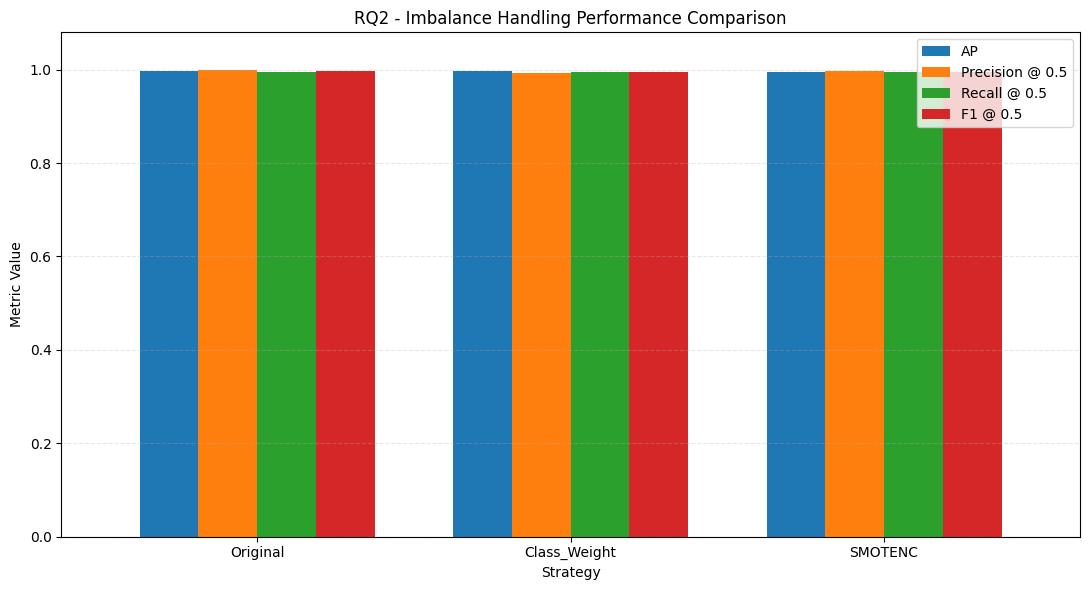

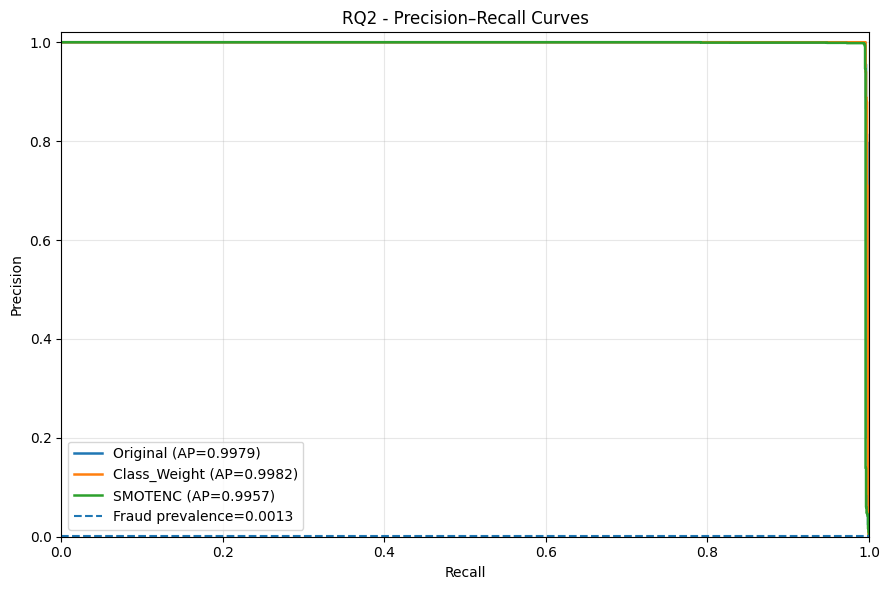

PASS: RQ2 visualization completed.
1. /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ2/figures/rq2_performance_comparison.png
2. /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ2/figures/rq2_pr_curves.png


In [ ]:
# ============================================================
# RQ2-08 — VISUALIZATION
# ============================================================

# ------------------------------------------------------------
# STEP 1. Performance Comparison
# ------------------------------------------------------------

plot_df = comparison_df.set_index("Strategy").loc[
    STRATEGIES
]

metrics_to_plot = [
    "AP",
    "Precision_at_0_5",
    "Recall_at_0_5",
    "F1_at_0_5"
]

ax = plot_df[metrics_to_plot].plot(
    kind="bar",
    figsize=(11, 6),
    width=0.75
)

ax.set_title(
    "RQ2 - Imbalance Handling Performance Comparison"
)

ax.set_ylabel("Metric Value")
ax.set_xlabel("Strategy")
ax.set_ylim(0, 1.08)

ax.set_xticklabels(
    STRATEGIES,
    rotation=0
)

ax.legend([
    "AP",
    "Precision @ 0.5",
    "Recall @ 0.5",
    "F1 @ 0.5"
])

ax.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

performance_path = (
    FIGURE_DIR / "rq2_performance_comparison.png"
)

plt.savefig(
    performance_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# STEP 2. Precision–Recall Curves
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 6))

for strategy in STRATEGIES:

    scores = validated_scores[strategy]

    precision, recall, _ = precision_recall_curve(
        y_val,
        scores
    )

    ap = average_precision_score(
        y_val,
        scores
    )

    ax.plot(
        recall,
        precision,
        label=f"{strategy} (AP={ap:.4f})",
        linewidth=1.8
    )

# Fraud prevalence làm baseline tham chiếu.
fraud_prevalence = float(y_val.mean())

ax.axhline(
    fraud_prevalence,
    linestyle="--",
    label=f"Fraud prevalence={fraud_prevalence:.4f}"
)

ax.set_title(
    "RQ2 - Precision–Recall Curves"
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

pr_path = FIGURE_DIR / "rq2_pr_curves.png"

plt.savefig(
    pr_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("PASS: RQ2 visualization completed.")
print("1.", performance_path)
print("2.", pr_path)

In [ ]:
# ============================================================
# RQ2-09 — FINAL STRATEGY SELECTION
# ============================================================

import json
import pandas as pd

# ------------------------------------------------------------
# STEP 1. Đọc kết quả đã lưu
# ------------------------------------------------------------

comparison_path = (
    RESULT_DIR / "rq2_comparison.csv"
)

assert comparison_path.is_file()

final_comparison = pd.read_csv(comparison_path)

required_strategies = {
    "Original",
    "Class_Weight",
    "SMOTENC"
}

assert set(final_comparison["Strategy"]) == required_strategies
assert final_comparison["Strategy"].is_unique
assert final_comparison["AP"].between(0, 1).all()

# ------------------------------------------------------------
# STEP 2. Chọn strategy theo AP trên Validation
# ------------------------------------------------------------

ranking = final_comparison.sort_values(
    by=["AP", "ROC_AUC"],
    ascending=[False, False]
).reset_index(drop=True)

selected_strategy = str(
    ranking.iloc[0]["Strategy"]
)

selected_ap = float(
    ranking.iloc[0]["AP"]
)

runner_up = str(
    ranking.iloc[1]["Strategy"]
)

ap_difference = float(
    ranking.iloc[0]["AP"] - ranking.iloc[1]["AP"]
)

# ------------------------------------------------------------
# STEP 3. Xác định file model tương ứng
# ------------------------------------------------------------

model_paths = {
    "Original": (
        RQ1_DIR / "models" / "XGBoost.joblib"
    ),
    "Class_Weight": (
        MODEL_DIR / "Class_Weight.joblib"
    ),
    "SMOTENC": (
        MODEL_DIR / "SMOTENC.joblib"
    )
}

selected_model_path = model_paths[selected_strategy]

selected_scores_path = (
    RESULT_DIR /
    f"{selected_strategy}_validation_scores.parquet"
)

preprocessor_path = (
    PP_DIR / "preprocessor_Tree.joblib"
)

for path in [
    selected_model_path,
    selected_scores_path,
    preprocessor_path
]:
    assert path.is_file(), f"Thiếu artifact: {path}"

# ------------------------------------------------------------
# STEP 4. Lưu cấu hình chính thức cho RQ3
# ------------------------------------------------------------

selection = {
    "research_question": "RQ2",

    "selected_algorithm": "XGBoost",
    "selected_strategy": selected_strategy,

    "selection_metric": "AP",
    "selection_dataset": "Validation_20pct",
    "selection_metric_value": selected_ap,

    "runner_up_strategy": runner_up,
    "ap_difference_vs_runner_up": ap_difference,

    "selected_model_path": str(selected_model_path),
    "selected_scores_path": str(selected_scores_path),
    "preprocessor_path": str(preprocessor_path),

    "validation_data_path": str(
        PP_DIR / "3.2.7_Tree_Validation_20pct.parquet"
    ),

    "preprocessing_family": "Tree",
    "feature_set": "Full_Features",

    "target_column": "isFraud",
    "reference_threshold": 0.5,

    "random_state": SEED,

    "class_weight_rule": (
        "n_negative / n_positive on Train"
    ),

    "smotenc_sampling_strategy": 0.02,
    "smotenc_categorical_features": ["type"],

    "selection_rationale": (
        "Highest Average Precision on the predefined "
        "Validation partition among Original, "
        "Class Weight and SMOTENC."
    ),

    "test_used_for_selection": False,

    "limitations": [
        "Only one Class Weight configuration was evaluated.",
        "Only one SMOTENC sampling ratio was evaluated.",
        "Synthetic samples may not satisfy every real-world "
        "transactional constraint.",
        "Fraud scores are not assumed to be calibrated.",
        "Performance generalization beyond the simulated "
        "dataset remains unverified."
    ]
}

selection_path = (
    RESULT_DIR / "selected_strategy.json"
)

with open(
    selection_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        selection,
        f,
        ensure_ascii=False,
        indent=2
    )

# ------------------------------------------------------------
# STEP 5. Kiểm tra kết quả sau khi lưu
# ------------------------------------------------------------

with open(
    selection_path,
    "r",
    encoding="utf-8"
) as f:
    saved_selection = json.load(f)

assert saved_selection["selected_strategy"] == selected_strategy
assert saved_selection["test_used_for_selection"] is False

print("=" * 55)
print("RQ2 STRATEGY SELECTION COMPLETED")
print("=" * 55)

print("Selected algorithm: XGBoost")
print("Selected strategy:", selected_strategy)
print("Validation AP:", round(selected_ap, 6))
print("Runner-up:", runner_up)
print("AP difference:", round(ap_difference, 6))

print("\nSaved:", selection_path)
print("\nPASS: RQ2 is ready for RQ3.")

RQ2 STRATEGY SELECTION COMPLETED
Selected algorithm: XGBoost
Selected strategy: Class_Weight
Validation AP: 0.998196
Runner-up: Original
AP difference: 0.000333

Saved: /content/drive/Shareddrives/M(anchine) L(earning)/Output/ML_Experiments/RQ2/results/selected_strategy.json

PASS: RQ2 is ready for RQ3.


In [ ]:
# ============================================================
# RQ2-10 — PREPROCESSING MODULE INTEGRITY CHECK
# ============================================================

from pathlib import Path
import importlib
import inspect
import hashlib

# 1. Đường dẫn module được mong đợi.
expected_path = (
    PP_DIR / "fraud_preprocessing.py"
).resolve()

print("Expected module:", expected_path)
print("File exists:", expected_path.is_file())

assert expected_path.is_file(), (
    "Không tìm thấy fraud_preprocessing.py "
    "trong thư mục Preprocessing."
)

# 2. Kiểm tra module hiện đang được nạp.
# Không reload tự động để tránh thay đổi trạng thái.
assert "fp" in globals(), (
    "Biến fp chưa tồn tại trong phiên Colab hiện tại."
)

actual_path = Path(
    inspect.getfile(fp)
).resolve()

print("\nLoaded module:", actual_path)

assert actual_path == expected_path, (
    "Module fp không được import từ đúng đường dẫn!"
)

# 3. Xác nhận những thành phần RQ2 sử dụng.
required_attributes = [
    "BASE_FEATURES",
    "TARGET",
    "TRANSACTION_TYPES",
    "FEATURES",
    "engineer_features"
]

for attr in required_attributes:
    assert hasattr(fp, attr), (
        f"Module thiếu: {attr}"
    )

print("\nRequired attributes: PASS")

# 4. Kiểm tra số features.
assert len(fp.BASE_FEATURES) == 7
assert len(fp.FEATURES) == 9
assert fp.TARGET == "isFraud"

print("Feature schema: PASS")

# 5. Tạo mã nhận diện phiên bản file hiện tại.
module_hash = hashlib.sha256(
    expected_path.read_bytes()
).hexdigest()

print("\nModule SHA256:", module_hash)

# 6. Kiểm tra các artifact RQ2 đã lưu.
artifacts = {
    "Class Weight model":
        MODEL_DIR / "Class_Weight.joblib",

    "SMOTENC model":
        MODEL_DIR / "SMOTENC.joblib",

    "RQ2 comparison":
        RESULT_DIR / "rq2_comparison.csv",

    "Selected strategy":
        RESULT_DIR / "selected_strategy.json"
}

for name, path in artifacts.items():
    exists = path.is_file() and path.stat().st_size > 0
    print(f"{name}: {'PASS' if exists else 'MISSING'}")
    assert exists

print("\nPASS: Module path and RQ2 artifacts verified.")

Expected module: /content/drive/Shareddrives/M(anchine) L(earning)/Output/Preprocessing/fraud_preprocessing.py
File exists: True

Loaded module: /content/drive/Shareddrives/M(anchine) L(earning)/Output/Preprocessing/fraud_preprocessing.py

Required attributes: PASS
Feature schema: PASS

Module SHA256: 4ff64f840f6d60ef7a5db51e92b877d09fe2fbf42fe050dd59b7a94bb0043f34
Class Weight model: PASS
SMOTENC model: PASS
RQ2 comparison: PASS
Selected strategy: PASS

PASS: Module path and RQ2 artifacts verified.
